# Leave-one-out cross-validation (and the PRESS shortcut)

**PSD I — Lecture 08, Modelling: Regression** 
Philipp Schlatter
2026 Institute of Fluid Mechanics (LSTM), FAU Erlangen-Nürnberg

Companion notebook to the slide set *L08b — Cross-Validation: Leave-One-Out*.

---

The training error of a regression model is not a measure of how well it will predict **new**
data: every measurement helped to place the very curve it is then compared against. To estimate
the *generalisation error* honestly we must keep data out of the fit.

**Leave-one-out (LOO)** cross-validation does this with the least possible waste. For each
$i = 1,\dots,N$:

1. remove point $i$ from the data,
2. fit the model to the remaining $N-1$ points, giving coefficients $p^{(-i)}$,
3. use that fit to predict the point that was withheld, $\hat{y}_i^{(-i)} = f(x_i;\,p^{(-i)})$.

The LOO error is the mean square of those $N$ genuinely out-of-sample residuals,

$$ CV_{(N)} \;=\; \frac{1}{N}\sum_{i=1}^{N}\bigl(y_i - \hat{y}_i^{(-i)}\bigr)^2 . $$

Done literally this costs $N$ fits. For a model that is **linear in its coefficients** the
**PRESS** identity gives exactly the same number from a *single* fit — that is the second half
of this notebook.

**Contents**

1. A five-point example, by hand
2. LOO for a general design matrix
3. The PRESS shortcut and the hat matrix
4. Leverage: which points flatter themselves
5. Choosing the model order with $CV_{(N)}$
6. PRESS for ridge regression
7. LOO vs $K$-fold
8. Exercises

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

# House style, so the plots match the lecture slides
plt.rcParams.update({
    "figure.figsize": (7.0, 4.0),
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "lines.linewidth": 1.8,
})

BLUE, RED, GREEN, GREY = "#1d4ed8", "#be123c", "#047857", "#64748b"

## 1. A five-point example

Five measurements, to be described by a straight line $\hat{y} = a_0 + a_1 x$.
Small enough that every number can be checked by hand.

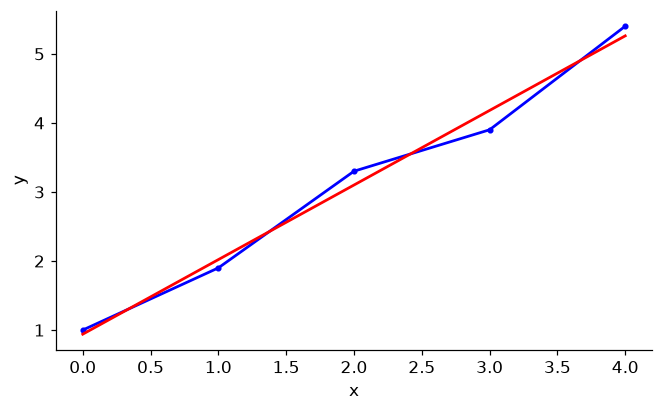

a0 = 0.9400,  a1 = 1.0800
in-sample residuals y - yhat : [ 0.06 -0.12  0.2  -0.28  0.14]
in-sample MSE               : 0.0312


In [5]:
x = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
y = np.array([1.0, 1.9, 3.3, 3.9, 5.4])

# the ordinary fit, using all five points
a1_full, a0_full = np.polyfit(x, y, 1)
yhat_full = a0_full + a1_full * x

plt.figure()
plt.plot(x,y,'.-b')
plt.xlabel('x')
plt.ylabel('y')
plt.plot(x,yhat_full,'r')
plt.show()

print(f"a0 = {a0_full:.4f},  a1 = {a1_full:.4f}")
print("in-sample residuals y - yhat :", y - yhat_full)
print(f"in-sample MSE               : {np.mean((y - yhat_full)**2):.4f}")

Now the same fit, five times over, each time with one point held back.

In [6]:
def loo_residuals_poly(x, y, order=1):
    """Leave-one-out residuals y_i - yhat_i^(-i) for a polynomial fit.

    The brute-force definition: N separate fits, each on N-1 points.
    """
    N = len(x)
    e = np.empty(N)
    for i in range(N):
        keep = np.ones(N, dtype=bool)
        keep[i] = False                        # leave point i out
        p = np.polyfit(x[keep], y[keep], order)  # fit on the other N-1
        e[i] = y[i] - np.polyval(p, x[i])        # predict the withheld point
    return e


e_loo = loo_residuals_poly(x, y, order=1)
CV = np.mean(e_loo**2)

print("LOO residuals y - yhat^(-i) :", e_loo)
print(f"CV_(N)                      : {CV:.4f}")
print(f"sqrt(CV_(N))                : {np.sqrt(CV):.4f}")

LOO residuals y - yhat^(-i) : [ 0.15   -0.1714  0.25   -0.4     0.35  ]
CV_(N)                      : 0.0794
sqrt(CV_(N))                : 0.2817


Side by side, the two sets of residuals make the point of the whole exercise:

In [7]:
header = f"{'i':>3} {'x':>5} {'y':>6} {'yhat':>8} {'y-yhat':>9} {'yhat^(-i)':>11} {'LOO resid':>11}"
print(header)
print("-" * len(header))
for i in range(len(x)):
    print(f"{i+1:>3} {x[i]:>5.1f} {y[i]:>6.2f} {yhat_full[i]:>8.2f} "
          f"{y[i]-yhat_full[i]:>+9.2f} {y[i]-e_loo[i]:>11.2f} {e_loo[i]:>+11.2f}")

print()
print(f"in-sample MSE : {np.mean((y - yhat_full)**2):.4f}")
print(f"CV_(N)        : {CV:.4f}   <-- about 2.5x larger, and the honest one")

  i     x      y     yhat    y-yhat   yhat^(-i)   LOO resid
-----------------------------------------------------------
  1   0.0   1.00     0.94     +0.06        0.85       +0.15
  2   1.0   1.90     2.02     -0.12        2.07       -0.17
  3   2.0   3.30     3.10     +0.20        3.05       +0.25
  4   3.0   3.90     4.18     -0.28        4.30       -0.40
  5   4.0   5.40     5.26     +0.14        5.05       +0.35

in-sample MSE : 0.0312
CV_(N)        : 0.0794   <-- about 2.5x larger, and the honest one


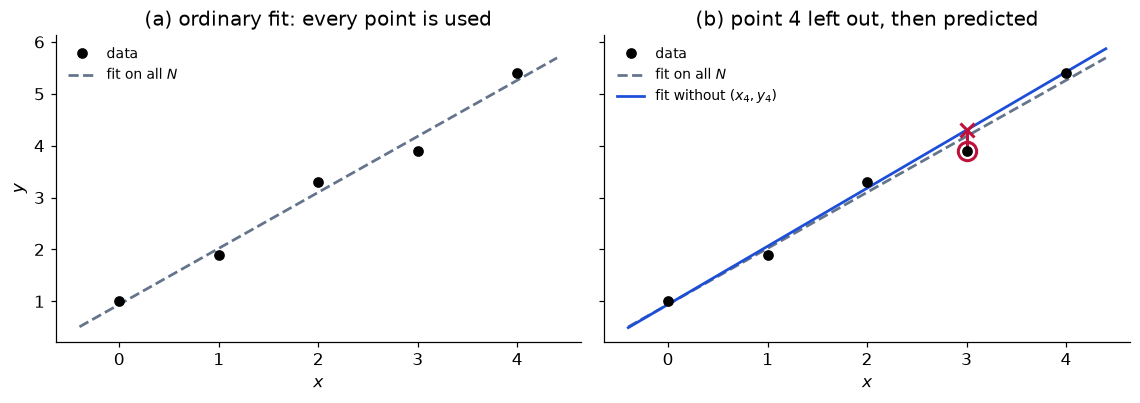

In [8]:
# the same picture as on the slides
left_out = 3                                  # index of point 4
keep = np.ones(len(x), bool); keep[left_out] = False
a1_part, a0_part = np.polyfit(x[keep], y[keep], 1)
xx = np.linspace(-0.4, 4.4, 100)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, cut in zip(axes, [None, left_out]):
    ax.plot(x, y, "o", color="black", ms=6, zorder=3, label="data")
    ax.plot(xx, a0_full + a1_full * xx, "--", color=GREY, label="fit on all $N$")
    if cut is not None:
        ax.plot(xx, a0_part + a1_part * xx, "-", color=BLUE,
                label="fit without $(x_4, y_4)$")
        yp = a0_part + a1_part * x[cut]
        ax.plot([x[cut]] * 2, [y[cut], yp], "-", color=RED, lw=2)
        ax.plot(x[cut], y[cut], "o", color=RED, ms=12, mfc="none", mew=2)
        ax.plot(x[cut], yp, "x", color=RED, ms=9, mew=2)
        ax.set_title("(b) point 4 left out, then predicted")
    else:
        ax.set_title("(a) ordinary fit: every point is used")
    ax.set_xlabel("$x$"); ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("$y$")
fig.tight_layout();

## 2. LOO for a general design matrix

`np.polyfit` is convenient but limited to polynomials. The general linear model of the lecture is

$$ \hat{y} = A\,p , \qquad
A_{ij} = f_j(x_i), \qquad j = 0,\dots,k-1 $$

with arbitrary shape functions $f_j$ — powers, sines, radial basis functions, anything, as long as
the model is **linear in the coefficients** $p$. The LOO loop is the same; only the solver changes.

In [9]:
def design_poly(x, order):
    """Vandermonde design matrix for a polynomial of the given order."""
    return np.vander(x, order + 1, increasing=True)


def fit(A, y):
    """Least-squares coefficients, via SVD (never via the normal equations)."""
    return np.linalg.lstsq(A, y, rcond=None)[0]


def loo_residuals(A, y):
    """Brute-force leave-one-out residuals for the linear model yhat = A p."""
    N = len(y)
    e = np.empty(N)
    for i in range(N):
        keep = np.ones(N, dtype=bool)
        keep[i] = False
        p = fit(A[keep], y[keep])
        e[i] = y[i] - A[i] @ p
    return e


A = design_poly(x, 1)
print("design matrix A =\n", A)
print("\nLOO residuals   :", loo_residuals(A, y))
print("same as before  :", np.allclose(loo_residuals(A, y), e_loo))

design matrix A =
 [[1. 0.]
 [1. 1.]
 [1. 2.]
 [1. 3.]
 [1. 4.]]

LOO residuals   : [ 0.15   -0.1714  0.25   -0.4     0.35  ]
same as before  : True


## 3. The PRESS shortcut

Refitting $N$ times is wasteful. Write the fitted values of the **single** full fit as

$$ \hat{\mathbf{y}} = M\,\mathbf{y}, \qquad M = A\,(A^{\mathsf T}A)^{-1}A^{\mathsf T} $$

$M$ is the *hat matrix* — it is usually written $H$, but in this course $H$ already denotes the
sum of squared errors, so we call it $M$. It is the orthogonal projector onto the column space of
$A$: it takes the measurements and projects them onto what the model is able to represent.

A short algebraic identity then gives every leave-one-out residual directly:

$$ y_i - \hat{y}_i^{(-i)} = \frac{y_i - \hat{y}_i}{1 - M_{ii}}
\qquad\Longrightarrow\qquad
CV_{(N)} = \frac{1}{N}\sum_{i=1}^{N}\left(\frac{y_i - \hat{y}_i}{1 - M_{ii}}\right)^2 $$

This is the **PRESS** statistic (*predicted residual error sum of squares*). One fit, not $N$.

In [10]:
def hat_matrix(A):
    """M = A (A^T A)^-1 A^T, computed via the pseudo-inverse for stability."""
    return A @ np.linalg.pinv(A)


def press_residuals(A, y):
    """Leave-one-out residuals from a single fit, via the PRESS identity."""
    M = hat_matrix(A)
    r = y - M @ y                       # ordinary in-sample residuals
    return r / (1.0 - np.diag(M))


def cv_loo(A, y):
    """The leave-one-out error CV_(N) of a linear model, cheaply."""
    return np.mean(press_residuals(A, y) ** 2)


A = design_poly(x, 1)
print("brute force :", loo_residuals(A, y))
print("PRESS       :", press_residuals(A, y))
print("identical   :", np.allclose(loo_residuals(A, y), press_residuals(A, y)))
print(f"\nCV_(N) = {cv_loo(A, y):.4f}")

brute force : [ 0.15   -0.1714  0.25   -0.4     0.35  ]
PRESS       : [ 0.15   -0.1714  0.25   -0.4     0.35  ]
identical   : True

CV_(N) = 0.0794


Worth pausing on: the right-hand column was obtained **without ever refitting**. The ordinary
residuals of one fit, each divided by $1 - M_{ii}$, *are* the leave-one-out residuals.

## 4. Leverage

$M_{ii} \in [0,1]$ is the **leverage** of point $i$: how strongly that measurement pulls the fit
towards itself. A point with leverage close to $1$ almost dictates its own prediction, so its
in-sample residual is misleadingly small — and $1/(1-M_{ii})$ inflates it accordingly.

For a straight line the leverage is largest at the ends of the $x$-range, where a point has the
most influence on the slope.

In [11]:
M = hat_matrix(design_poly(x, 1))
h = np.diag(M)

print("leverage M_ii :", h)
print("sum of M_ii   :", h.sum(), " (= k, the number of coefficients)")
print()
for i in range(len(x)):
    r = y[i] - yhat_full[i]
    print(f"point {i+1}:  residual {r:+.3f} / (1 - {h[i]:.2f}) = {r/(1-h[i]):+.3f}")

leverage M_ii : [0.6 0.3 0.2 0.3 0.6]
sum of M_ii   : 1.9999999999999996  (= k, the number of coefficients)

point 1:  residual +0.060 / (1 - 0.60) = +0.150
point 2:  residual -0.120 / (1 - 0.30) = -0.171
point 3:  residual +0.200 / (1 - 0.20) = +0.250
point 4:  residual -0.280 / (1 - 0.30) = -0.400
point 5:  residual +0.140 / (1 - 0.60) = +0.350


The leverages sum to $k$, the number of fitted coefficients — a useful sanity check, and the
reason the $N-k$ in the residual variance $\sigma_y^2$ of the lecture appears where it does.

With more data the pattern is clearer: leverage is a U-shaped function of $x$ for a line, and
grows with the model order.

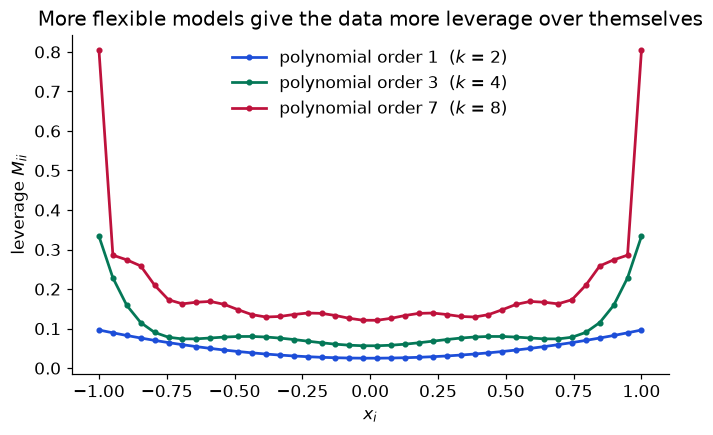

In [12]:
xs = np.linspace(-1, 1, 40)
fig, ax = plt.subplots()
for order, col in zip([1, 3, 7], [BLUE, GREEN, RED]):
    ax.plot(xs, np.diag(hat_matrix(design_poly(xs, order))), "-o", ms=3,
            color=col, label=f"polynomial order {order}  ($k$ = {order+1})")
ax.set_xlabel("$x_i$"); ax.set_ylabel("leverage $M_{ii}$")
ax.set_title("More flexible models give the data more leverage over themselves")
ax.legend();

## 5. Choosing the model order with $CV_{(N)}$

This is what cross-validation is normally needed for. Data from a fixed underlying function plus
noise; polynomials of increasing order; training error against LOO error.

In [17]:
rng = np.random.default_rng(3)
xd = np.sort(rng.uniform(-1, 1, 25))
yd = np.sin(3.0 * xd) + 0.35 * xd**2 + rng.normal(0, 0.25, 25)

orders = np.arange(0, 11)
train, cv = [], []
for k in orders:
    Ak = design_poly(xd, k)
    p = fit(Ak, yd)
    train.append(np.mean((yd - Ak @ p) ** 2))
    cv.append(cv_loo(Ak, yd))                      # one fit per order, via PRESS

train, cv = np.array(train), np.array(cv)
best = int(orders[np.argmin(cv)])

print(f"{'order':>6} {'training MSE':>14} {'CV_(N)':>12}")
for k, t, c in zip(orders, train, cv):
    mark = "   <-- lowest CV" if k == best else ""
    print(f"{k:>6} {t:>14.4f} {c:>12.4f}{mark}")

 order   training MSE       CV_(N)
     0         0.6034       0.6547
     1         0.2802       0.3390
     2         0.2261       0.3289
     3         0.0566       0.0818
     4         0.0525       0.0812   <-- lowest CV
     5         0.0514       0.0816
     6         0.0514       0.1622
     7         0.0510       0.2967
     8         0.0509       1.9362
     9         0.0459       0.2039
    10         0.0447       8.0531


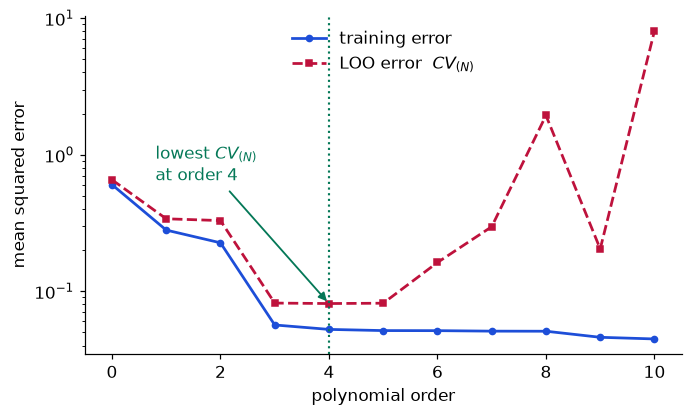

In [18]:
fig, ax = plt.subplots()
ax.semilogy(orders, train, "-o", color=BLUE, ms=4, label="training error")
ax.semilogy(orders, cv, "--s", color=RED, ms=4, label="LOO error  $CV_{(N)}$")
ax.axvline(best, color=GREEN, ls=":", lw=1.4)
ax.annotate(f"lowest $CV_{{(N)}}$\nat order {best}", xy=(best, cv.min()),
            xytext=(best - 3.2, cv.min() * 8), color=GREEN,
            arrowprops=dict(arrowstyle="-|>", color=GREEN, lw=1.2))
ax.set_xlabel("polynomial order"); ax.set_ylabel("mean squared error")
ax.set_xticks(orders[::2]); ax.legend(loc="upper center");

The training error falls monotonically, as it always must — more features can always fit the
training data at least as well. The LOO error does not: it bottoms out at a moderate order and
then grows by orders of magnitude. That is overfitting, made visible and quantitative.

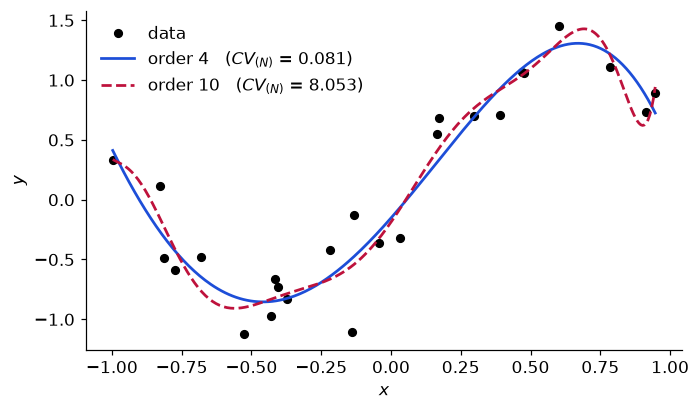

In [19]:
# what the selected model actually looks like, against an over-flexible one
xx = np.linspace(xd.min(), xd.max(), 300)
fig, ax = plt.subplots()
ax.plot(xd, yd, "o", color="black", ms=5, label="data")
for k, col, ls in [(best, BLUE, "-"), (10, RED, "--")]:
    p = fit(design_poly(xd, k), yd)
    ax.plot(xx, design_poly(xx, k) @ p, ls, color=col,
            label=f"order {k}   ($CV_{{(N)}}$ = {cv[k]:.3f})")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.legend();

## 6. PRESS for ridge regression

The identity holds for any *linear smoother*, that is, any method whose predictions are a fixed
linear map of the measurements, $\hat{\mathbf{y}} = M\mathbf{y}$. Ridge regression qualifies, with

$$ M(\alpha) = A\,(A^{\mathsf T}A + \alpha I)^{-1}A^{\mathsf T} $$

so the regularisation weight $\alpha$ can be selected by exactly the same sweep — one fit per
candidate $\alpha$, no refitting.

*(Standardise the columns of $A$ first: the penalty acts on the numerical size of the
coefficients, so features on different scales would be penalised inconsistently.)*

best alpha = 3.625,  CV_(N) = 0.1744
unregularised (alpha -> 0): CV_(N) = 153.2255


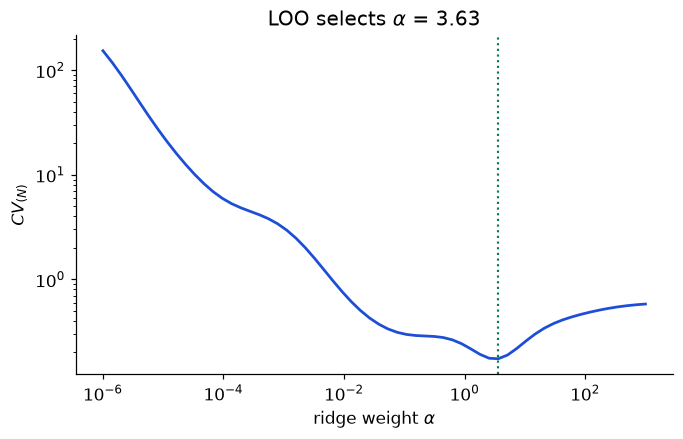

In [20]:
def ridge_hat(A, alpha):
    """Hat matrix of ridge regression with weight alpha."""
    k = A.shape[1]
    return A @ np.linalg.solve(A.T @ A + alpha * np.eye(k), A.T)


def cv_loo_ridge(A, y, alpha):
    M = ridge_hat(A, alpha)
    r = y - M @ y
    return np.mean((r / (1.0 - np.diag(M))) ** 2)


# an over-flexible basis, deliberately: order 12 for 25 points
Ar = design_poly(xd, 12)
Ar_std = (Ar - Ar.mean(0)) / np.where(Ar.std(0) > 0, Ar.std(0), 1.0)
Ar_std[:, 0] = 1.0                                    # keep an unpenalised intercept

alphas = np.logspace(-6, 3, 60)
cv_a = np.array([cv_loo_ridge(Ar_std, yd, a) for a in alphas])
a_best = alphas[np.argmin(cv_a)]

fig, ax = plt.subplots()
ax.loglog(alphas, cv_a, color=BLUE)
ax.axvline(a_best, color=GREEN, ls=":", lw=1.4)
ax.set_xlabel(r"ridge weight $\alpha$"); ax.set_ylabel("$CV_{(N)}$")
ax.set_title(r"LOO selects $\alpha$ = %.3g" % a_best);
print(f"best alpha = {a_best:.4g},  CV_(N) = {cv_a.min():.4f}")
print(f"unregularised (alpha -> 0): CV_(N) = {cv_a[0]:.4f}")

Regularisation rescues the over-flexible model dramatically — $CV_{(N)}$ falls from about $153$
at $\alpha\to0$ to $0.17$ at the selected weight. It does *not* beat simply choosing the right
model order, though: the order-4 polynomial of section 5 reached $CV_{(N)}\approx0.08$. Picking
the basis and tuning the penalty are complementary, and $CV_{(N)}$ is the common currency in
which both choices are made.

## 7. LOO versus $K$-fold

LOO is $K$-fold cross-validation with $K = N$. $K$-fold leaves out a whole block at a time: $K$
fits instead of $N$, which is what makes it the default once $N$ is large or a single fit is
expensive. The price is a slightly pessimistic estimate, because each fit sees only
$N(1 - 1/K)$ of the data.

In [21]:
def cv_kfold(A, y, K=5, seed=0):
    """K-fold cross-validated mean squared error."""
    N = len(y)
    idx = np.random.default_rng(seed).permutation(N)
    folds = np.array_split(idx, K)
    err = []
    for f in folds:
        keep = np.ones(N, dtype=bool)
        keep[f] = False
        p = fit(A[keep], y[keep])
        err.extend((y[f] - A[f] @ p) ** 2)
    return float(np.mean(err))


Ab = design_poly(xd, best)
print(f"LOO    (K = N = {len(yd)}) : {cv_loo(Ab, yd):.4f}")
for K in (10, 5, 3):
    vals = [cv_kfold(Ab, yd, K, seed=s) for s in range(20)]
    print(f"{K:>2}-fold             : {np.mean(vals):.4f}   "
          f"(spread over 20 shuffles: {np.std(vals):.4f})")

LOO    (K = N = 25) : 0.0812
10-fold             : 0.0803   (spread over 20 shuffles: 0.0051)
 5-fold             : 0.0889   (spread over 20 shuffles: 0.0115)
 3-fold             : 0.1007   (spread over 20 shuffles: 0.0518)


Note the last column: a $K$-fold estimate depends on how the data happened to be shuffled, and
that scatter does not shrink as $K$ falls. LOO has no such arbitrariness — but its own estimate
has the higher variance across *data sets*, because the $N$ fits differ by one point each and
their errors are therefore strongly correlated.

**Rule of thumb** — small $N$ with a model linear in its coefficients (use PRESS): LOO.
Large $N$, or an expensive nonlinear fit: $K$-fold with $K = 5\dots10$.

## 8. Exercises

1. Add an outlier to the five-point data set (say $y_3 = 5.0$) and recompute both the in-sample
   and the LOO residuals. Which one notices?
2. Move the five $x$-values closer together, except one. What happens to the leverages, and to
   $CV_{(N)}$?
3. Verify numerically that $\sum_i M_{ii} = k$ for several orders $k$, and explain the connection
   to the $N - k$ in the residual variance $\sigma_y^2$ of the lecture.
4. Replace the polynomial basis by $\{1, x, \sin(x), \cos(x)\}$ and compare $CV_{(N)}$ with the
   polynomial of the same number of coefficients. Which basis suits this data better?
5. The PRESS identity fails for nonlinear regression. Take $y = \beta_2 e^{\beta_1 x}$, fit it with
   `scipy.optimize.curve_fit`, and compute the LOO error the slow way. How much does the
   logarithmic transform of the lecture change the answer?

---

*PSD I | Philipp Schlatter | philipp.schlatter@fau.de*